# Project 6: Image enhancement Techniques

this is a three part project where we create functions for:

1. Histogram Equalization
2. Histogram Equalization in grayscale
3. Smothening (reducing noise)


check:
- https://scikit-image.org/
- https://binarybits.hashnode.dev/histogram-equalization
- 



# Imports

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

from cv_utils import (
    display,
    display_grid,
    ImageLoader,
)

In [ ]:
import os
from pathlib import Path
from dotenv import load_dotenv

load_dotenv()
PROJECT_ROOT = Path(os.getenv("PROJECT_ROOT"))
DATA_DIR = Path(os.getenv("DATA_DIR"))

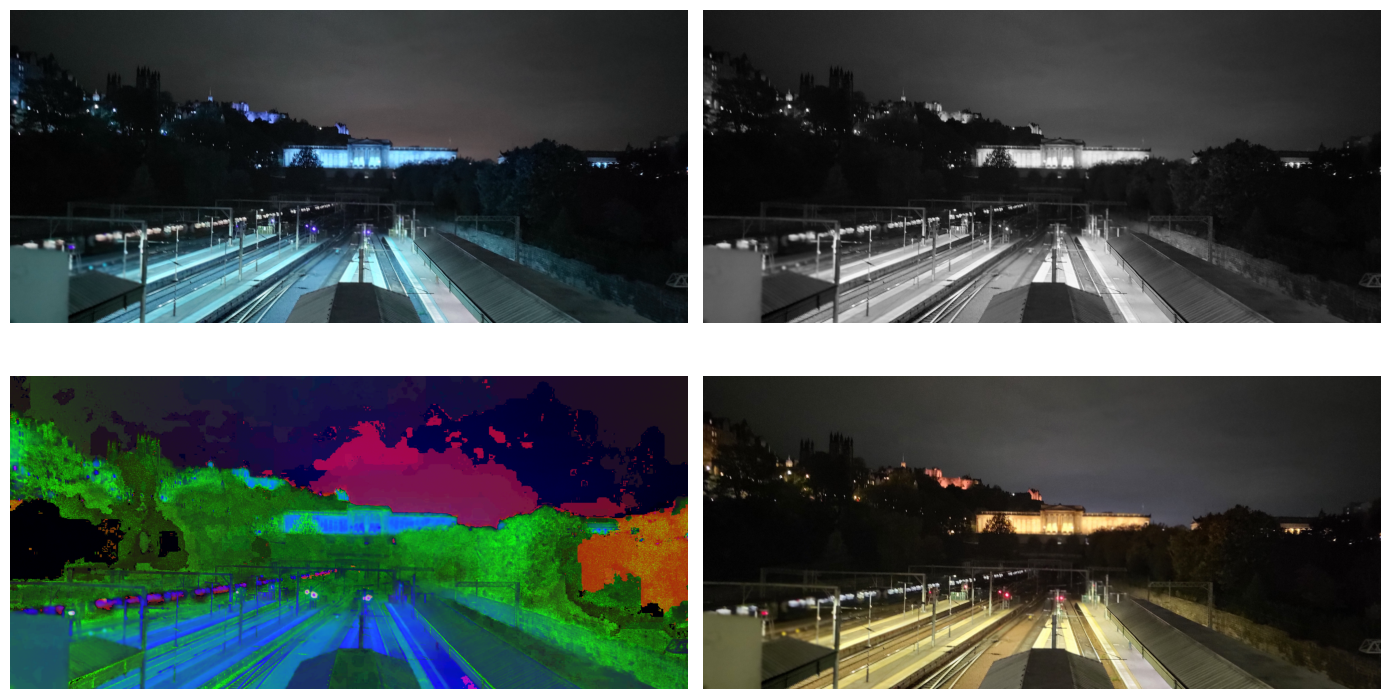

In [19]:
image_path = DATA_DIR / "bad_lighting_edinbourgh.jpg"

img_bgr, img_gs, img_hsv, img_rgb = ImageLoader.load_bgr_gs_hsv_rgb(image_path)

display_grid([img_bgr, img_gs, img_hsv, img_rgb], "grey")

### defining funcs for histogram plots

In [20]:
def plot_histogram_bgr(img):
    colors = ("b", "g", "r")
    for channel, color in enumerate(colors):
        hist = cv2.calcHist([img],
                            channels=[channel],
                            mask=None,
                            histSize=[256],
                            ranges=[0, 256],
        )
        plt.plot(hist, color=color)
    plt.title("BGR Histograms")
    plt.show()

def plot_histogram_rgb(img):
    colors = ("r", "g", "b")
    for channel, color in enumerate(colors):
        hist = cv2.calcHist([img],
                            channels = [channel],
                            mask = None,
                            histSize = [256],
                            ranges = [0, 256]
        )
        plt.plot(hist, color=color)
    plt.title("RGB Histograms")
    plt.show()

def plot_histogram_gs(img):
    hist = cv2.calcHist([img],
                        channels = [0],
                        mask = None,
                        histSize = [256],
                        ranges = [0, 256]
    )
    plt.plot(hist)
    plt.title("Grayscale Histogram")
    plt.show()

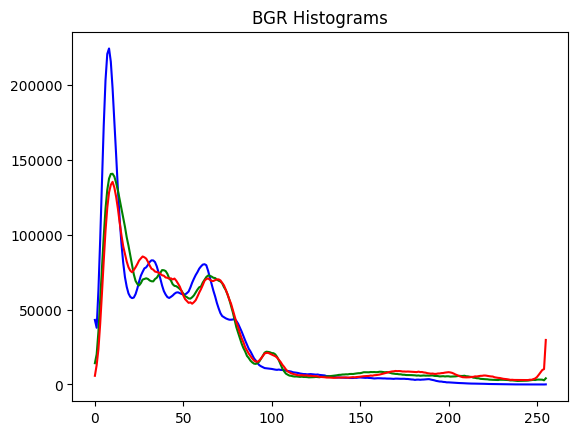

In [21]:
plot_histogram_bgr(img_bgr)

---

# 1. Histogram Equalization

Histogram equalization is a technique that improves the
contrast in an image by redistributing the intensity
values. This is particularly useful for images with poor
lighting conditions. Create function called

    - enhance_lightning(image_bgr) -> image_bgr

that can help us to send in bgr colored system image
and enhance it and return it as bgr. create a demo and
show the enhancement.



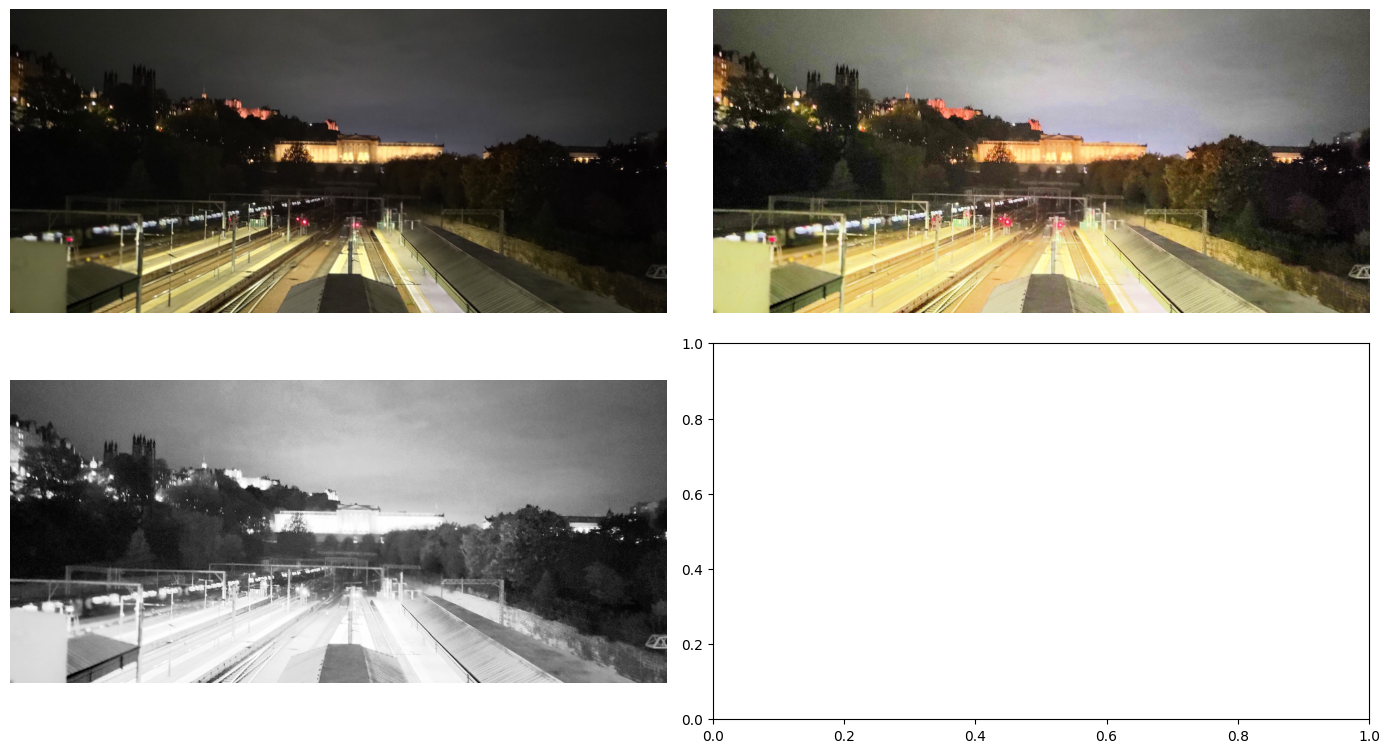

In [ ]:
# add loading with imageloader if img_bgr == path!

def enhance_lightning_bgr(img_bgr) -> np.ndarray:
    """Equalizes with hsv. Takes and returns BGR."""
    # convert to hsv, and equalize
    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    img_hsv[:,:,2] = cv2.equalizeHist(img_hsv[:,:,2])
    # return a rgb - convert back from hsv
    return cv2.cvtColor(img_hsv, cv2.COLOR_HSV2BGR)


img_bgr_eq = enhance_lightning_bgr(img_bgr)
img_rgb_eq = cv2.cvtColor(img_bgr_eq, cv2.COLOR_BGR2RGB)

img_bgr_eq_2 = cv2.equalizeHist(img_bgr[:,:,2])
img_rgb_eq_2 = cv2.cvtColor(img_bgr_eq_2, cv2.COLOR_BGR2RGB)



display_grid([img_rgb, img_rgb_eq, img_rgb_eq_2])

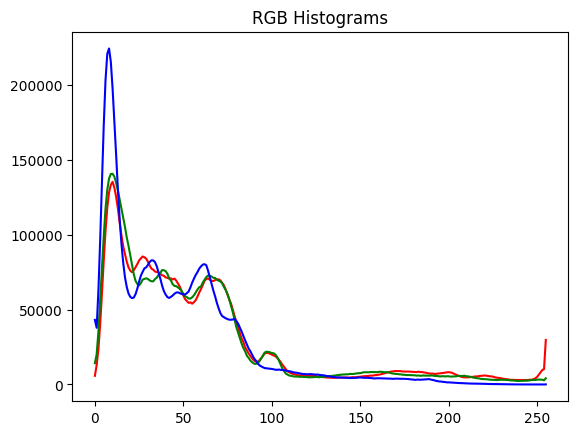

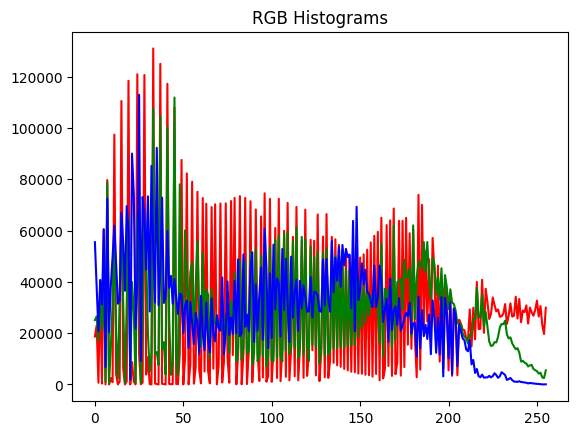

In [23]:
plot_histogram_rgb(img_rgb)
plot_histogram_rgb(img_rgb_eq)

---

# 2. Histogram Equalization Grayscale

Now we need to enhance contrast and lightning for gray
scaled images using same technique histogram
equalization create function called:

    - enhance_lightning_g(image_GRAY) -> image_GRAY

that can help us to send in Gray scaled colored system
image and enhance it and return it as Gray scaled also.
create a demo and show the enhancement.

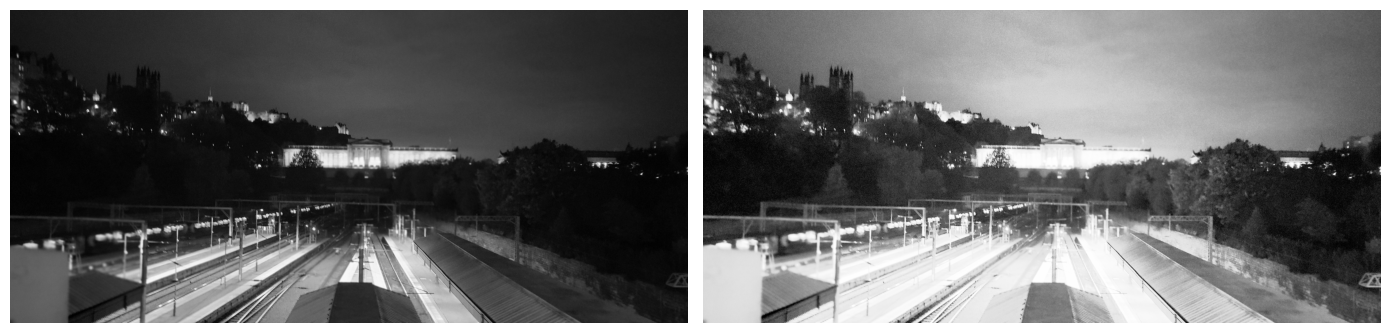

In [24]:
# add loading with imageloader if img_bgr == path!

def enhance_lightning_gs(img_gs) -> np.ndarray:
    return cv2.equalizeHist(img_gs)

img_gs_eq = enhance_lightning_gs(img_gs)

display_grid([img_gs, img_gs_eq], "grey")

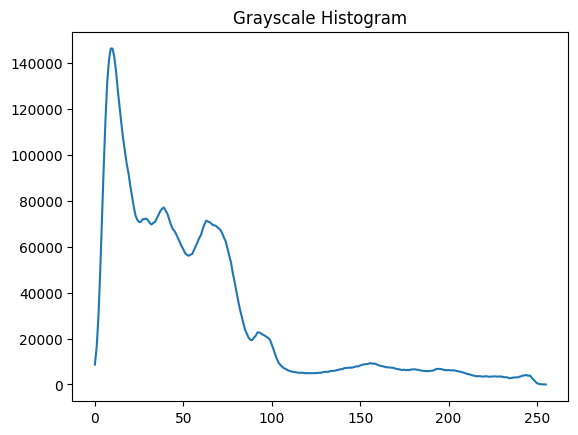

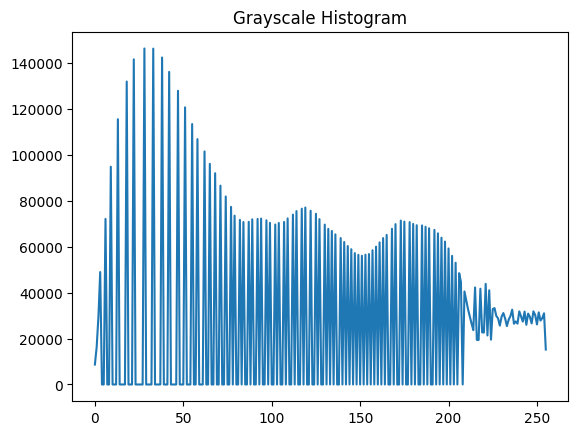

In [25]:
plot_histogram_gs(img_gs)
plot_histogram_gs(img_gs_eq)